# Phần 3.1 — Ghép torrent với phim: phương pháp và chất lượng tích hợp

Chương 3 phân tích **phim lậu**. Trước hết phải trả lời: *mỗi torrent là phim nào?* MagnetDB không có khóa phim chuẩn, nên đây là bài toán **ghép thực thể (entity matching)** — phần cốt lõi của tích hợp dữ liệu. Hai nguồn ghép được dùng song song:

1. **Mã IMDb có sẵn của MagnetDB** (`movieMatchTitleId`, cấp file, chỉ các ca `matchScore > 138`) — có lỗi và phủ thấp.
2. **Tự ghép tên torrent** (`src/04_match_torrent_names.py`): tách *tên + năm* từ tên torrent bằng biểu thức chính quy trong DuckDB, tra chính xác trong chỉ mục tên IMDb (gồm `title.akas`), bỏ các ca mơ hồ.

Sau đó gộp và lọc chung (`src/09_build_tables.py`, 10 bước A–J). Biểu đồ lưu vào `plots/6_integration/`.

In [1]:
# Tìm thư mục gốc dự án (chứa src/viz_style.py) để import phong cách biểu đồ dùng chung
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "viz_style.py").exists())
sys.path.insert(0, str(ROOT / "src"))
%matplotlib inline

## Nạp dữ liệu

In [2]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

import viz_style as V

V.setup()
FOLDER = "6_integration"
SRC = "Nguồn: MagnetDB, IMDb, TMDb; xử lý của nhóm."
P = lambda name: (V.DC / name).as_posix()
con = duckdb.connect()
log = pd.read_csv(V.DC / "cleaning_log.csv")
tor = duckdb.sql(f"SELECT torrent_id, imdb_id, source, discovered_at_utc, implausible, in_stable_window "
                 f"FROM read_parquet('{P('torrents_clean.parquet')}')").df()
ok = tor[~tor["implausible"]]
print(f"{len(ok):,} cặp torrent–phim sạch; {ok['torrent_id'].nunique():,} torrent; {ok['imdb_id'].nunique():,} phim")

2,078,927 cặp torrent–phim sạch; 2,066,598 torrent; 126,081 phim


## 1. Mỗi bước làm sạch loại bỏ bao nhiêu?

  wrote plots\6_integration\01_cleaning_funnel.png


WindowsPath('D:/dulieulon/plots/6_integration/01_cleaning_funnel.png')

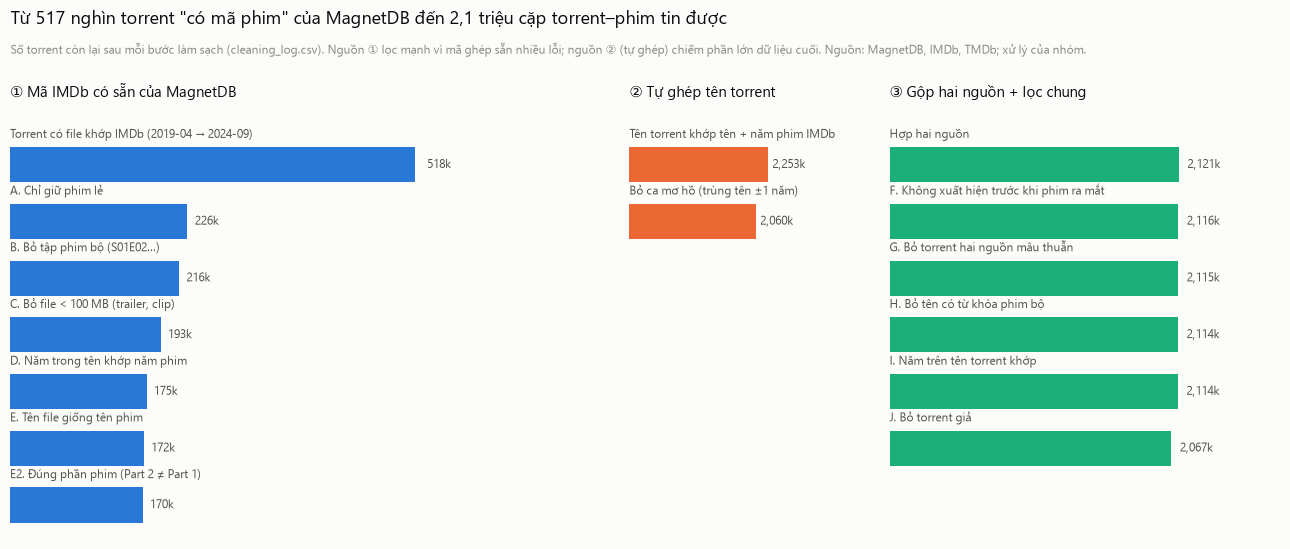

In [3]:
LABELS = {
    "0. slice 2019-04 -> 2024-09 (mọi loại)": "Torrent có file khớp IMDb (2019-04 → 2024-09)",
    "A. chỉ PHIM (titleType=movie)": "A. Chỉ giữ phim lẻ",
    "B. bỏ file có số mùa/tập": "B. Bỏ tập phim bộ (S01E02…)",
    f"C. bỏ file < 100MB": "C. Bỏ file < 100 MB (trailer, clip)",
    "D. năm trong tên file khớp năm phim (±1)": "D. Năm trong tên khớp năm phim",
    "E. tên file giống tên phim >= 60": "E. Tên file giống tên phim",
    "E2. số phần phim khớp (Part 2 ≠ Part 1)": "E2. Đúng phần phim (Part 2 ≠ Part 1)",
    "0. ghép được (tên + năm khớp IMDb)": "Tên torrent khớp tên + năm phim IMDb",
    "bỏ ca mơ hồ (>1 phim trùng tên ±1 năm)": "Bỏ ca mơ hồ (trùng tên ±1 năm)",
    "hợp hai nguồn": "Hợp hai nguồn",
    "F. không xuất hiện trước ra mắt > 60 ngày": "F. Không xuất hiện trước khi phim ra mắt",
    "G. bỏ torrent hai nguồn mâu thuẫn": "G. Bỏ torrent hai nguồn mâu thuẫn",
    "H. bỏ tên torrent có từ khóa phim bộ": "H. Bỏ tên có từ khóa phim bộ",
    "I. năm trên tên torrent khớp năm phim (trừ gói)": "I. Năm trên tên torrent khớp",
    "J. bỏ torrent không hợp lý (bản nét trước ngày phát hành)": "J. Bỏ torrent giả",
}
log = log[log["step"].isin(LABELS)].drop_duplicates("step")
panels = [("magnetdb", "① Mã IMDb có sẵn của MagnetDB", V.BLUE),
          ("name_match", "② Tự ghép tên torrent", V.ORANGE),
          ("combined", "③ Gộp hai nguồn + lọc chung", V.AQUA)]
fig, axes = plt.subplots(1, 3, figsize=(13, 5.6), gridspec_kw=dict(width_ratios=[7, 2.4, 5]))
for ax, (src, name, color) in zip(axes, panels):
    d = log[log["source"] == src].reset_index(drop=True)
    y = np.arange(len(d))[::-1]
    base = d["torrents"].iloc[0]
    ax.barh(y, d["torrents"], color=color, height=0.62)
    for yi, v, step in zip(y, d["torrents"], d["step"]):
        ax.text(v * 1.02 + base * 0.01, yi, f"{v / 1e3:,.0f}k", va="center", color=V.INK2, fontsize=8.5)
        ax.text(0, yi + 0.42, LABELS[step], va="bottom", color=V.INK2, fontsize=8.5)
    ax.set_xlim(0, base * 1.35)
    ax.set_ylim(len(d) - 7.6, len(d) - 0.1)          # cùng số "khe" ở mọi bảng -> thanh dày như nhau
    ax.set_yticks([])
    ax.set_xticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(name, loc="left", color=V.INK, fontsize=10.5, pad=12)
V.titles(fig, "Từ 517 nghìn torrent \"có mã phim\" của MagnetDB đến 2,1 triệu cặp torrent–phim tin được",
         f"Số torrent còn lại sau mỗi bước làm sạch (cleaning_log.csv). Nguồn ① lọc mạnh vì mã ghép sẵn nhiều lỗi; nguồn ② "
         f"(tự ghép) chiếm phần lớn dữ liệu cuối. {SRC}")
V.save(fig, FOLDER, "01_cleaning_funnel")

**Nhận xét.** Nguồn ① giảm mạnh từ **518k → 170k torrent**: phần lớn bị loại vì là phim bộ hoặc không phải phim (bước A), rồi các lỗi ghép (năm không khớp, tên không giống, sai phần phim). Nguồn ② tự ghép tên torrent cho **~2,25 triệu** torrent, bỏ ~8% ca mơ hồ (trùng tên nhiều phim, tên quá chung chung như "New", "Cricket"). Sau khi gộp và lọc chung (bỏ torrent xuất hiện trước khi phim tồn tại, mâu thuẫn giữa hai nguồn, torrent giả) còn **~2,07 triệu torrent sạch**.

## 2. Tự ghép tên torrent thêm được bao nhiêu dữ liệu?

  wrote plots\6_integration\02_coverage_by_source.png


WindowsPath('D:/dulieulon/plots/6_integration/02_coverage_by_source.png')

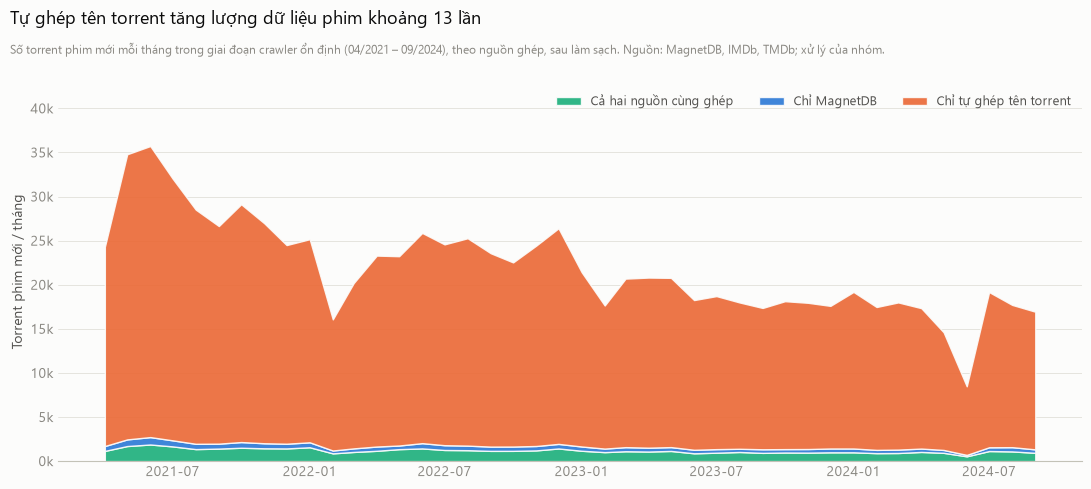

In [4]:
m = ok.assign(month=ok["discovered_at_utc"].dt.to_period("M").dt.to_timestamp())
m = m.drop_duplicates(["torrent_id", "source"]).pivot_table(index="month", columns="source", values="torrent_id",
                                                              aggfunc="count", fill_value=0)
m = m[(m.index >= "2021-04-01") & (m.index < "2024-10-01")]
SRCS = [("both", "Cả hai nguồn cùng ghép", V.AQUA), ("magnetdb", "Chỉ MagnetDB", V.BLUE),
        ("name_match", "Chỉ tự ghép tên torrent", V.ORANGE)]
fig, ax = plt.subplots(figsize=(11, 5))
V.style_axes(ax)
ax.stackplot(m.index, [m[s] for s, _, _ in SRCS], colors=[c for _, _, c in SRCS], labels=[l for _, l, _ in SRCS],
             edgecolor=V.SURFACE, linewidth=1, alpha=0.9)
ratio = m.sum(axis=1).sum() / (m["both"] + m["magnetdb"]).sum()
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1e3:.0f}k"))
ax.set_ylabel("Torrent phim mới / tháng")
ax.legend(loc="upper right", ncol=3)
ax.set_ylim(0, m.sum(axis=1).max() * 1.2)
V.titles(fig, f"Tự ghép tên torrent tăng lượng dữ liệu phim khoảng {ratio:.0f} lần",
         f"Số torrent phim mới mỗi tháng trong giai đoạn crawler ổn định (04/2021 – 09/2024), theo nguồn ghép, sau làm sạch. {SRC}")
V.save(fig, FOLDER, "02_coverage_by_source")

**Nhận xét.** Phần màu cam (chỉ tự ghép mới tìm ra) chiếm gần hết: lượng torrent phim tăng **khoảng 14 lần** so với chỉ dùng mã có sẵn. Lý do: MagnetDB *tách tên đúng nhưng tra IMDb sai* rồi loại vì điểm thấp — vd. `Deadpool.2016.1080p.BluRay` bị ghép với một video ca nhạc "Deadpool (feat. Deadpool)" (điểm 11/138).

## 3. Điều gì xảy ra nếu chỉ dùng dữ liệu có sẵn?

  wrote plots\6_integration\03_top_movies_dumbbell.png


WindowsPath('D:/dulieulon/plots/6_integration/03_top_movies_dumbbell.png')

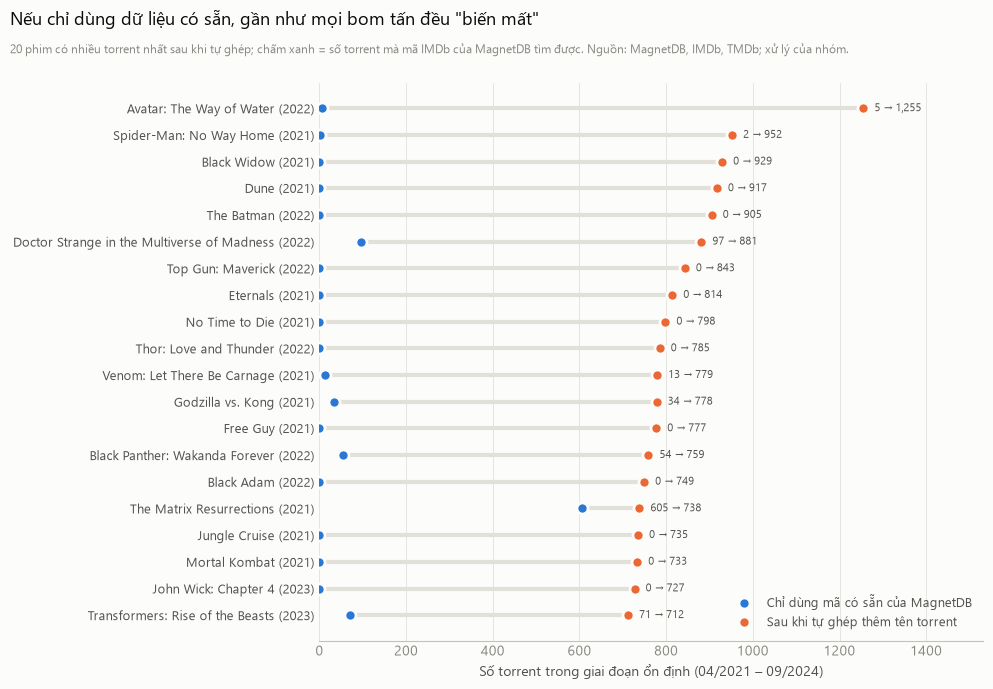

In [5]:
mv = duckdb.sql(f"SELECT title, start_year, n_torrents_stable, n_torrents_stable_magnetdb "
                f"FROM read_parquet('{P('movie_analysis.parquet')}') ORDER BY n_torrents_stable DESC LIMIT 20").df()[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
V.style_axes(ax, grid="x")
y = np.arange(len(mv))
ax.hlines(y, mv["n_torrents_stable_magnetdb"], mv["n_torrents_stable"], color=V.GRID, linewidth=3)
ax.plot(mv["n_torrents_stable_magnetdb"], y, "o", markersize=8, color=V.BLUE, markeredgecolor=V.SURFACE,
        markeredgewidth=2, label="Chỉ dùng mã có sẵn của MagnetDB")
ax.plot(mv["n_torrents_stable"], y, "o", markersize=8, color=V.ORANGE, markeredgecolor=V.SURFACE,
        markeredgewidth=2, label="Sau khi tự ghép thêm tên torrent")
for yi, a, b in zip(y, mv["n_torrents_stable_magnetdb"], mv["n_torrents_stable"]):
    ax.annotate(f"{a:,} → {b:,}", xy=(b, yi), xytext=(8, 0), textcoords="offset points", va="center",
                color=V.INK2, fontsize=8)
ax.set_yticks(y)
ax.set_yticklabels([f"{t} ({yr})" for t, yr in zip(mv["title"], mv["start_year"])], color=V.INK2, fontsize=9)
ax.set_xlim(0, mv["n_torrents_stable"].max() * 1.22)
ax.set_xlabel("Số torrent trong giai đoạn ổn định (04/2021 – 09/2024)")
ax.legend(loc="lower right")
V.titles(fig, "Nếu chỉ dùng dữ liệu có sẵn, gần như mọi bom tấn đều \"biến mất\"",
         f"20 phim có nhiều torrent nhất sau khi tự ghép; chấm xanh = số torrent mà mã IMDb của MagnetDB tìm được. {SRC}")
V.save(fig, FOLDER, "03_top_movies_dumbbell")

**Nhận xét.** Gần như **mọi bom tấn "biến mất"**: *Top Gun: Maverick, Dune, The Batman, Black Widow…* có 0 torrent theo mã của MagnetDB, nhưng 700–950 torrent sau khi tự ghép. Chỉ *The Matrix Resurrections* được MagnetDB ghép tốt. Mọi kết luận về phim lậu dựa trên dữ liệu gốc sẽ sai lệch nghiêm trọng — đây là đóng góp quan trọng nhất của bước tích hợp.

## 4. Phép ghép đáng tin đến đâu?

đồng thuận tự ghép vs MagnetDB gốc: 0.817 (131,418); vs MagnetDB đã làm sạch: 0.994 (107,957)
  wrote plots\6_integration\04_match_agreement.png


WindowsPath('D:/dulieulon/plots/6_integration/04_match_agreement.png')

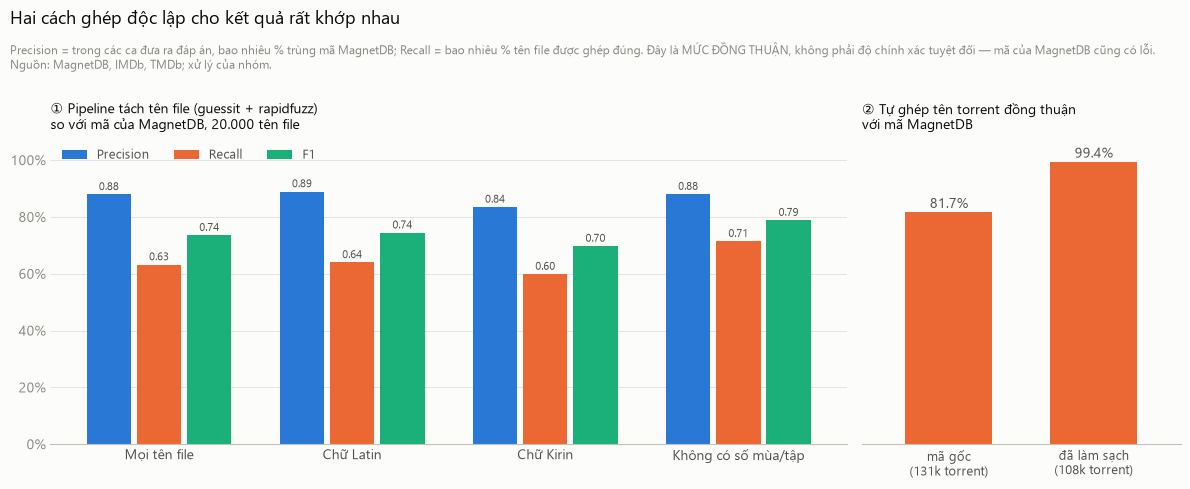

In [6]:
ev = duckdb.sql(f"SELECT * FROM read_parquet('{P('match_eval.parquet')}')").df()


def prf(df):
    n_pred, n_ok = df["pred"].notna().sum(), (df["pred"] == df["truth"]).sum()
    p, r = n_ok / max(n_pred, 1), n_ok / max(len(df), 1)
    return pd.Series({"Precision": p, "Recall": r, "F1": 2 * p * r / (p + r) if p + r else 0})


groups = {"Mọi tên file": ev, "Chữ Latin": ev[ev["script"] == "latin/other"], "Chữ Kirin": ev[ev["script"] == "cyrillic"],
          "Không có số mùa/tập": ev[~ev["is_tv_hint"]]}
tab = pd.DataFrame({k: prf(v) for k, v in groups.items()}).T
# So với mã GỐC của MagnetDB (trước khi gộp/làm sạch, để hai bên độc lập): chỉ torrent mà
# MagnetDB gán đúng 1 phim, không phải tập phim bộ, file >= 100 MB.
agree = con.execute(f"""
    WITH mdb AS (SELECT torrent_id, any_value(imdb_id) AS imdb_id
                 FROM read_parquet('{P('matched_files.parquet')}')
                 WHERE NOT is_tv_hint AND file_size >= 1e8
                 GROUP BY torrent_id HAVING count(DISTINCT imdb_id) = 1)
    SELECT avg((n.imdb_id = m.imdb_id)::INT), count(*)
    FROM read_parquet('{P('name_matches.parquet')}') n JOIN mdb m USING (torrent_id) WHERE NOT n.ambiguous
""").fetchone()
# So với MagnetDB SAU các bộ lọc A–E2 của chính nó nhưng TRƯỚC khi gộp (chưa bỏ ca mâu thuẫn)
agree_clean = con.execute(f"""
    WITH mdb AS (SELECT torrent_id, any_value(imdb_id) AS imdb_id
                 FROM read_parquet('{P('magnetdb_clean_pairs.parquet')}')
                 GROUP BY torrent_id HAVING count(DISTINCT imdb_id) = 1)
    SELECT avg((n.imdb_id = m.imdb_id)::INT), count(*)
    FROM read_parquet('{P('name_matches.parquet')}') n JOIN mdb m USING (torrent_id) WHERE NOT n.ambiguous
""").fetchone()
print(f"đồng thuận tự ghép vs MagnetDB gốc: {agree[0]:.3f} ({agree[1]:,}); vs MagnetDB đã làm sạch: "
      f"{agree_clean[0]:.3f} ({agree_clean[1]:,})")
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw=dict(width_ratios=[3, 1.2]))
V.style_axes(ax)
x = np.arange(len(tab))
w = 0.26
for i, (col, color) in enumerate(zip(tab.columns, V.CAT[:3])):
    bars = ax.bar(x + (i - 1) * w, tab[col], width=w - 0.03, color=color, label=col)
    for b, v in zip(bars, tab[col]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.2f}", ha="center", color=V.INK2, fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(tab.index, color=V.INK2)
ax.set_ylim(0, 1.08)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(loc="upper left", ncol=3)
ax.set_title("① Pipeline tách tên file (guessit + rapidfuzz)\nso với mã của MagnetDB, 20.000 tên file", loc="left",
             color=V.INK, fontsize=10)
V.style_axes(ax2, grid=None)
for xi, (val, n) in enumerate([agree, agree_clean]):
    ax2.bar([xi], [val], width=0.6, color=V.ORANGE)
    ax2.text(xi, val + 0.015, f"{val:.1%}", ha="center", color=V.INK2, fontsize=10)
ax2.set_xticks([0, 1])
ax2.set_xticklabels([f"mã gốc\n({agree[1] / 1e3:,.0f}k torrent)", f"đã làm sạch\n({agree_clean[1] / 1e3:,.0f}k torrent)"],
                    color=V.INK2, fontsize=9)
ax2.set_ylim(0, 1.08)
ax2.set_yticks([])
ax2.set_xlim(-0.6, 1.6)
ax2.set_title("② Tự ghép tên torrent đồng thuận\nvới mã MagnetDB", loc="left", color=V.INK, fontsize=10)
V.titles(fig, "Hai cách ghép độc lập cho kết quả rất khớp nhau",
         f"Precision = trong các ca đưa ra đáp án, bao nhiêu % trùng mã MagnetDB; Recall = bao nhiêu % tên file được ghép đúng. "
         f"Đây là MỨC ĐỒNG THUẬN, không phải độ chính xác tuyệt đối — mã của MagnetDB cũng có lỗi. {SRC}")
V.save(fig, FOLDER, "04_match_agreement")

**Nhận xét.** ① Pipeline tách tên file (guessit + rapidfuzz) đạt **precision ~0,88** so với mã MagnetDB; recall thấp hơn (~0,63) vì cố tình bỏ phim bộ và tên Nga phiên âm Latin. ② Tự ghép tên torrent trùng **81,7%** với mã *gốc* của MagnetDB nhưng **99,4%** với mã MagnetDB *đã làm sạch* — khoảng chênh chính là các lỗi của mã gốc mà bước làm sạch đã loại. Lưu ý: đây là **mức đồng thuận** giữa hai phương pháp, không phải độ chính xác tuyệt đối; kiểm tra bằng mắt hàng trăm mẫu ngẫu nhiên cho thấy hầu hết đều đúng.

## Tóm tắt phần 3.1

| Khía cạnh | Kết quả |
|---|---|
| Dữ liệu cuối | ~2,07 triệu torrent sạch, ~126k phim |
| Độ phủ | Tự ghép tăng dữ liệu phim ~14 lần; bom tấn gần như không có trong dữ liệu gốc |
| Chất lượng | Đồng thuận 99,4% với mã MagnetDB đã làm sạch |
| Hạn chế | Cần năm trong tên torrent; bỏ phim trùng tên; ~1% có thể vẫn ghép sai |